In [36]:
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2


def setup_model(num_classes=2, freeze_backbone=True):
  # Load pretrained MobileNetV2 with modern weights parameter
  model = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)

  # Freeze backbone features to prevent overfitting on the small dataset
  if freeze_backbone:
    for param in model.parameters():
      param.requires_grad = False

  # Replace final classifier layer
  num_ftrs = model.classifier[1].in_features
  model.classifier[1] = nn.Linear(num_ftrs, num_classes)

  return model

In [37]:
# Initialize the MobileNetV2 model with frozen backbone
model = setup_model(num_classes=2, freeze_backbone=True)

# Move model to available device (GPU or CPU)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = model.to(device)

--- Έναρξη Φόρτωσης Δεδομένων ---
Ελέγχονται οι εικόνες από το αρχείο: train_data.txt...
 ⚠️ Αγνοήθηκε: Το ID 27035 δεν βρέθηκε στον φάκελο Neoplasia
 ⚠️ Αγνοήθηκε: Το ID 61820 δεν βρέθηκε στον φάκελο Neoplasia
 ⚠️ Αγνοήθηκε: Το ID 85578 δεν βρέθηκε στον φάκελο Neoplasia
 ⚠️ Αγνοήθηκε: Το ID 65713 δεν βρέθηκε στον φάκελο Neoplasia
 ⚠️ Αγνοήθηκε: Το ID 48507 δεν βρέθηκε στον φάκελο Neoplasia
 ⚠️ Αγνοήθηκε: Το ID 30716 δεν βρέθηκε στον φάκελο Neoplasia
 ⚠️ Αγνοήθηκε: Το ID 29576 δεν βρέθηκε στον φάκελο Non-neoplasia
--> Βρέθηκαν συνολικά 327 / 334 εικόνες.

Ελέγχονται οι εικόνες από το αρχείο: valid_data.txt...
--> Βρέθηκαν συνολικά 72 / 72 εικόνες.

Επιτυχία! Τα DataLoaders είναι έτοιμα.


In [ ]:
import torch


class EarlyStopping:

  def __init__(
      self,
      patience=5,
      verbose=False,
      delta=0,
      path="mobilenetv2_polyp_best.pth",
  ):
    self.patience = patience
    self.verbose = verbose
    self.counter = 0
    self.best_loss = None
    self.early_stop = False
    self.delta = delta
    self.path = path

  def __call__(self, val_loss, model):
    if self.best_loss is None:
      self.best_loss = val_loss
      self.save_checkpoint(val_loss, model)
    elif val_loss > self.best_loss - self.delta:
      self.counter += 1
      if self.verbose:
        print(
            f"EarlyStopping counter: {self.counter} out of {self.patience}"
        )
      if self.counter >= self.patience:
        self.early_stop = True
    else:
      self.best_loss = val_loss
      self.save_checkpoint(val_loss, model)
      self.counter = 0

  def save_checkpoint(self, val_loss, model):
    if self.verbose:
      print(
          f"Validation loss decreased ({self.best_loss:.6f} -->"
          f" {val_loss:.6f}). Saving model..."
      )
    torch.save(model.state_dict(), self.path)

In [ ]:
# Initialize the early stopping utility with the MobileNetV2 checkpoint path
early_stopping = EarlyStopping(
    patience=5, verbose=True, path="mobilenetv2_polyp_best.pth"
)

In [38]:
num_epochs = 20

train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("Starting MobileNetV2 training...\n" + "-" * 40)

import torch

torch.cuda.empty_cache()

for epoch in range(num_epochs):

  model.train()
  running_loss = 0.0
  correct, total = 0, 0

  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    running_loss += loss.item() * images.size(0)
    _, predicted = torch.max(outputs.data, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

  epoch_train_loss = running_loss / len(train_loader.dataset)
  epoch_train_acc = 100 * correct / total
  train_losses.append(epoch_train_loss)
  train_accs.append(epoch_train_acc)

  model.eval()
  val_loss = 0.0
  correct, total = 0, 0

  with torch.no_grad():
    for images, labels in val_loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)

      val_loss += loss.item() * images.size(0)
      _, predicted = torch.max(outputs.data, 1)
      total += labels.size(0)
      correct += (predicted == labels).sum().item()

  epoch_val_loss = val_loss / len(val_loader.dataset)
  epoch_val_acc = 100 * correct / total
  val_losses.append(epoch_val_loss)
  val_accs.append(epoch_val_acc)

  print(
      f"Epoch [{epoch+1}/{num_epochs}] | "
      f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | "
      f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.2f}%"
  )

  # Pass both validation loss and the model so checkpoints can be saved
  early_stopping(epoch_val_loss, model)
  if early_stopping.early_stop:
    print(
        "\nEarly Stopping triggered! Model stopped improving and best weights"
        " were saved."
    )
    break

print("-" * 40 + "\nTraining completed!")

Ξεκινάει η εκπαίδευση του ResNet18...
----------------------------------------
Epoch [1/20] | Train Loss: 0.7926, Train Acc: 65.75% | Val Loss: 0.9033, Val Acc: 61.11%
Epoch [2/20] | Train Loss: 0.5712, Train Acc: 72.17% | Val Loss: 0.6972, Val Acc: 70.83%
Epoch [3/20] | Train Loss: 0.5277, Train Acc: 72.17% | Val Loss: 0.6014, Val Acc: 69.44%
Epoch [4/20] | Train Loss: 0.4433, Train Acc: 79.51% | Val Loss: 0.6910, Val Acc: 68.06%
EarlyStopping counter: 1 out of 5
Epoch [5/20] | Train Loss: 0.3796, Train Acc: 81.04% | Val Loss: 0.9323, Val Acc: 69.44%
EarlyStopping counter: 2 out of 5
Epoch [6/20] | Train Loss: 0.2960, Train Acc: 84.71% | Val Loss: 0.9630, Val Acc: 75.00%
EarlyStopping counter: 3 out of 5
Epoch [7/20] | Train Loss: 0.3211, Train Acc: 85.02% | Val Loss: 0.8657, Val Acc: 66.67%
EarlyStopping counter: 4 out of 5
Epoch [8/20] | Train Loss: 0.3023, Train Acc: 88.07% | Val Loss: 0.8669, Val Acc: 70.83%
EarlyStopping counter: 5 out of 5

Ενεργοποιήθηκε το Early Stopping! Το μ

In [39]:
import torch
import gc

torch.save(model.state_dict(), 'resnet18_polyp_best.pth')
print("Το μοντέλο αποθηκεύτηκε με επιτυχία!")

gc.collect()
torch.cuda.empty_cache()

Το μοντέλο αποθηκεύτηκε με επιτυχία!


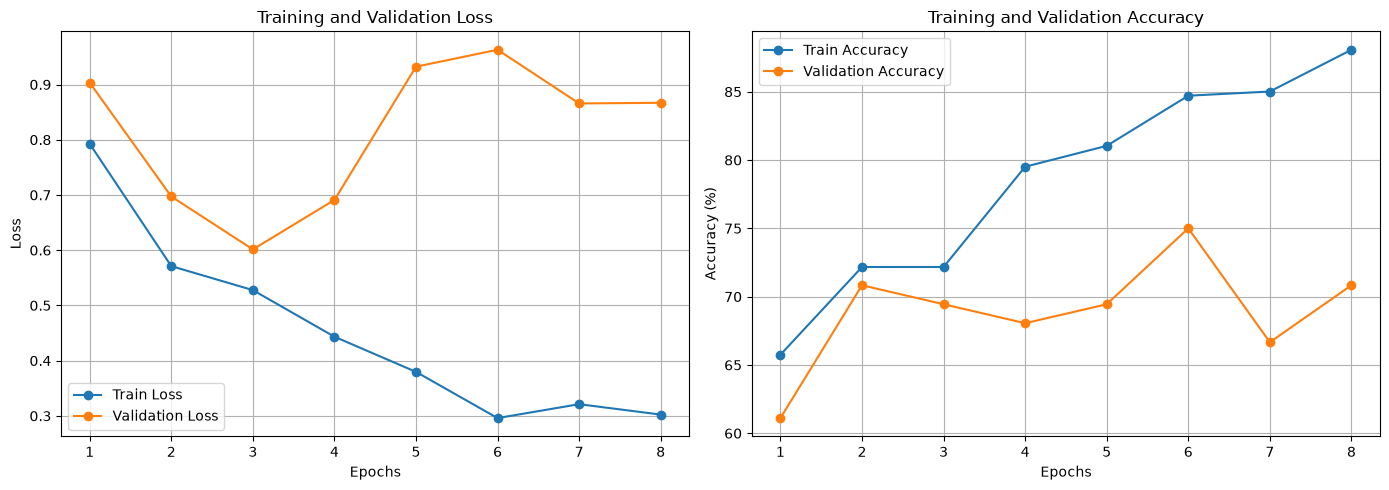

In [40]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Train Loss', marker='o')
plt.plot(epochs_range, val_losses, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accs, label='Train Accuracy', marker='o')
plt.plot(epochs_range, val_accs, label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

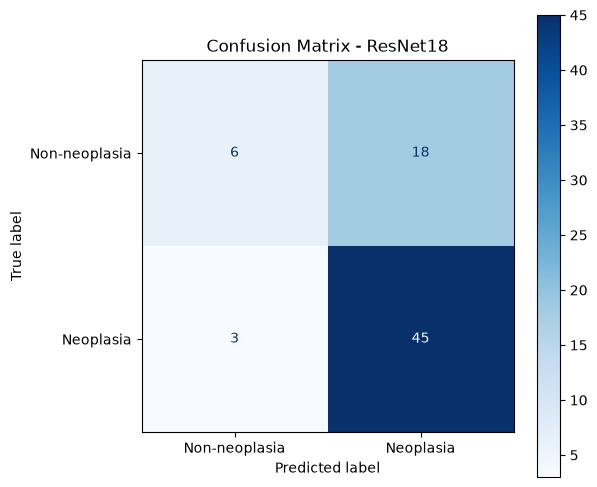

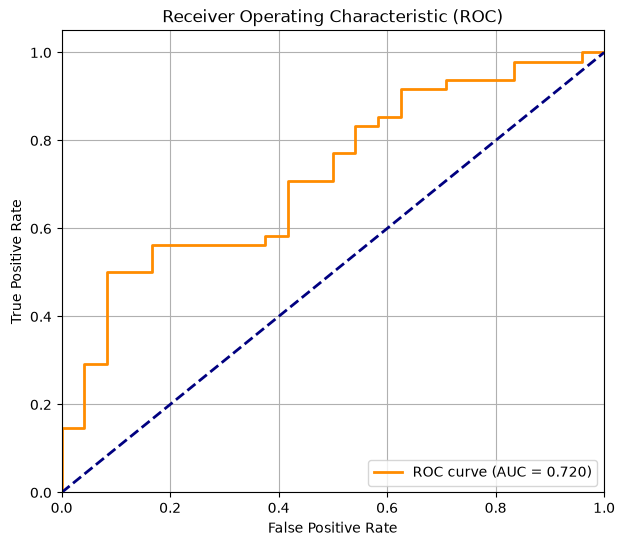

In [41]:
import torch
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import torch.nn.functional as F

model.eval()
all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = model(images)
 
        probs = F.softmax(outputs, dim=1)[:, 1] 
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-neoplasia', 'Neoplasia'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Confusion Matrix - ResNet18")
plt.show()

fpr, tpr, thresholds = roc_curve(all_labels, all_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [42]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import gc

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model.load_state_dict(torch.load('resnet18_polyp_best.pth'))
model.eval()

all_labels = []
all_probs = []
all_preds = []

print("Υπολογισμός μετρικών για τον Πίνακα 1...\n" + "-"*40)

with torch.no_grad():

    for images, labels in val_loader: 
        images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)[:, 1]
        preds = torch.argmax(outputs, dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

y_true = np.array(all_labels).flatten()
y_prob = np.array(all_probs).flatten()
y_pred = np.array(all_preds).flatten()

y_true = y_true.astype(int)
y_pred = y_pred.astype(int)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

accuracy = accuracy_score(y_true, y_pred) * 100
sensitivity = (tp / (tp + fn)) * 100
specificity = (tn / (tn + fp)) * 100
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print(f"Μοντέλο: model (Yours) | Pretrained 'or' Scratch: Scratch")
print("-" * 55)
print(f"Accuracy (%)   : {accuracy:.2f}")
print(f"Sensitivity (%): {sensitivity:.2f}")
print(f"Specificity (%): {specificity:.2f}")
print(f"F1 Score       : {f1:.4f}")
print(f"AUC            : {auc:.4f}")

Υπολογισμός μετρικών για τον Πίνακα 1...
----------------------------------------
Μοντέλο: model (Yours) | Pretrained 'or' Scratch: Scratch
-------------------------------------------------------
Accuracy (%)   : 70.83
Sensitivity (%): 93.75
Specificity (%): 25.00
F1 Score       : 0.8108
AUC            : 0.7205
